# EDA: Predict Future Sales

Короткий разбор данных. Выводы из него определяют протокол оценки (см. `docs/research_problem_statement.md`).

In [1]:
import os, sys
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, ".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import build_grid
from src.utils import load_config

cfg = load_config("configs/baseline.yaml")
D = Path(cfg["data_dir"])
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"eda_{name}.png", dpi=120); plt.show()

sales = pd.read_csv(D / "sales_train.csv", dtype={"date_block_num": "int8", "shop_id": "int8", "item_id": "int16",
                    "item_price": "float32", "item_cnt_day": "float32"})
test = pd.read_csv(D / "test.csv")
items = pd.read_csv(D / "items.csv")
cats = pd.read_csv(D / "item_categories.csv")
shops = pd.read_csv(D / "shops.csv")

## 1. Обзор данных

In [2]:
for f in ["sales_train", "test", "items", "item_categories", "shops"]:
    p = D / f"{f}.csv"
    print(f"{f:16s} {p.stat().st_size/1e6:7.1f} MB")
for name, d in [("sales", sales), ("test", test), ("items", items), ("cats", cats), ("shops", shops)]:
    print(f"\n{name}: shape {d.shape}, missing {int(d.isna().sum().sum())}, full duplicates {int(d.duplicated().sum())}")
    print(d.dtypes.to_string())
print("\nsales memory, MB:", round(sales.memory_usage(deep=True).sum()/1e6))
print("months:", sales.date_block_num.min(), "-", sales.date_block_num.max())

sales_train         94.6 MB
test                 3.2 MB
items                1.6 MB
item_categories      0.0 MB
shops                0.0 MB



sales: shape (2935849, 6), missing 0, full duplicates 6
date                  str
date_block_num       int8
shop_id              int8
item_id             int16
item_price        float32
item_cnt_day      float32

test: shape (214200, 3), missing 0, full duplicates 0
ID         int64
shop_id    int64
item_id    int64

items: shape (22170, 3), missing 0, full duplicates 0
item_name             str
item_id             int64
item_category_id    int64

cats: shape (84, 2), missing 0, full duplicates 0
item_category_name      str
item_category_id      int64

shops: shape (60, 2), missing 0, full duplicates 0
shop_name      str
shop_id      int64



sales memory, MB: 208
months: 0 - 33


## 2. Как устроен test

In [3]:
n_shops, n_items = test.shop_id.nunique(), test.item_id.nunique()
print(f"test {len(test)} = {n_shops} x {n_items} = {n_shops*n_items}; full product: {len(test) == n_shops*n_items and not test.duplicated(['shop_id','item_id']).any()}")
new_items = set(test.item_id) - set(sales.item_id)
print("new items in test:", len(new_items))

pairs = set(zip(sales.shop_id, sales.item_id))
seen_items = set(sales.item_id)
tp = list(zip(test.shop_id, test.item_id))
test["slice"] = np.where([p in pairs for p in tp], "A", np.where(test.item_id.isin(seen_items), "B", "C"))
print(test["slice"].value_counts().sort_index().to_frame("rows").assign(share=lambda d: (d.rows/len(test)).round(3)))

last = sales[sales.date_block_num == 33]
miss = sorted(set(last.shop_id) - set(test.shop_id))
print("shops active in month 33:", last.shop_id.nunique(), "| in test:", n_shops)
print(shops[shops.shop_id.isin(miss)].to_string(index=False))
print("shops in test but not in train:", sorted(set(test.shop_id) - set(sales.shop_id)))

test 214200 = 42 x 5100 = 214200; full product: True


new items in test:

 363
         rows  share
slice               
A      111404  0.520
B       87550  0.409
C       15246  0.071
shops active in month 33: 44 | in test: 42
          shop_name  shop_id
  Выездная Торговля        9
Москва "Распродажа"       20


shops in test but not in train: []


## 3. Выбросы и дубли магазинов

item_price min/max: -1.0 307980.0
price <= 0 rows: 1 | price > 100000 rows: 1
item_cnt_day max: 2169.0 | rows > 1000: 1
returns (cnt < 0): rows 7356 (0.25%), min -22


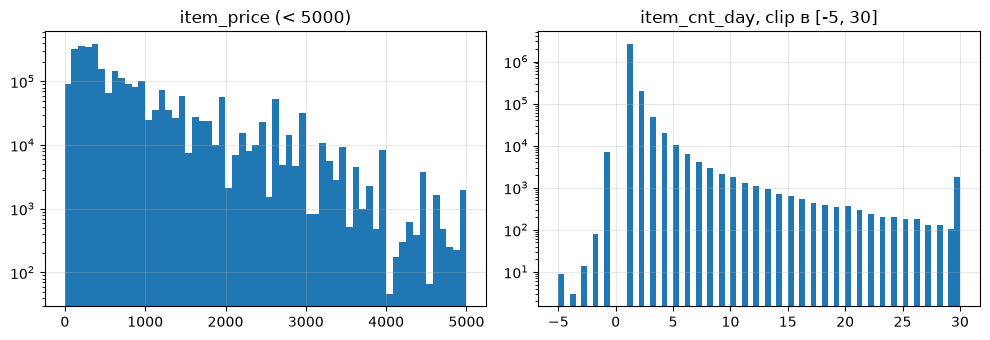


 0 '!Якутск Орджоникидзе, 56 фран'               months 0..1, active 2
57 'Якутск Орджоникидзе, 56'                     months 2..33, active 32

 1 '!Якутск ТЦ "Центральный" фран'               months 0..1, active 2
58 'Якутск ТЦ "Центральный"'                     months 2..33, active 32

10 'Жуковский ул. Чкалова 39м?'                  months 0..33, active 33
11 'Жуковский ул. Чкалова 39м²'                  months 25..25, active 1


In [4]:
print("item_price min/max:", sales.item_price.min(), sales.item_price.max())
print("price <= 0 rows:", (sales.item_price <= 0).sum(), "| price > 100000 rows:", (sales.item_price > 100000).sum())
print("item_cnt_day max:", sales.item_cnt_day.max(), "| rows > 1000:", (sales.item_cnt_day > 1000).sum())
neg = sales.item_cnt_day < 0
print("returns (cnt < 0): rows", neg.sum(), f"({neg.mean():.2%}), min {sales.item_cnt_day.min():.0f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(sales.item_price[sales.item_price < 5000], bins=60); ax[0].set_title("item_price (< 5000)"); ax[0].set_yscale("log")
ax[1].hist(sales.item_cnt_day.clip(-5, 30), bins=70); ax[1].set_title("item_cnt_day, clip в [-5, 30]"); ax[1].set_yscale("log")
save("outliers")

shop_name = shops.set_index("shop_id").shop_name
for a, b in [(0, 57), (1, 58), (10, 11)]:
    print()
    for s in (a, b):
        act = sorted(sales.loc[sales.shop_id == s, "date_block_num"].unique())
        print(f"{s:2d} {shop_name[s]!r:45} months {act[0]}..{act[-1]}, active {len(act)}")

## 4. Таргет

Строим сетку по протоколу: для каждого месяца магазины и товары, активные в этом месяце, перемножаются. Магазины 9 и 20 исключены, дубли объединены.

sales: 2935849 -> 2930297 rows after cleaning


grid: 11069101 rows total; month 33: 221802 rows = 42 shops x 5281 items; mean y 0.258; test rows 214200


pair-months in log: 1606737
share of monthly sums > 20: 0.70%
share of monthly sums <= 0: 0.22%

month 33 grid: 221802 rows, zeros 0.862, mean clipped y 0.258
month 33 logged pairs only: mean clipped y 1.858, mean raw y 2.051


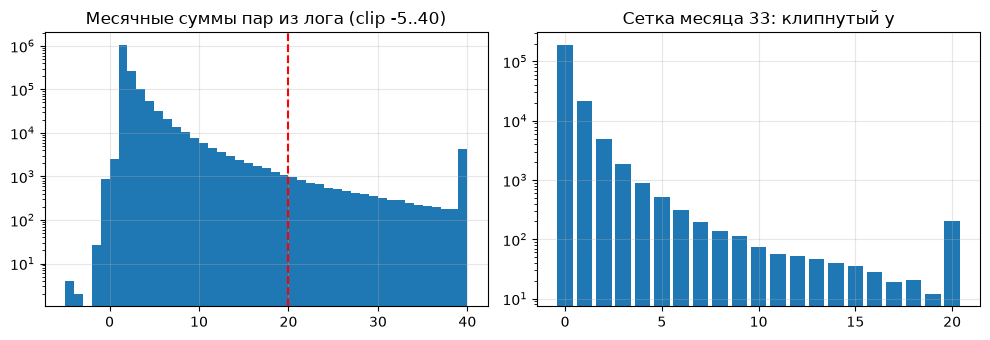

In [5]:
g = build_grid(cfg)
hist = g[g.date_block_num < 34]
logged = hist[hist.in_log]
print(f"pair-months in log: {len(logged)}")
print(f"share of monthly sums > 20: {(logged.y_raw > 20).mean():.2%}")
print(f"share of monthly sums <= 0: {(logged.y_raw <= 0).mean():.2%}")

m33 = hist[hist.date_block_num == 33]
print(f"\nmonth 33 grid: {len(m33)} rows, zeros {(m33.y == 0).mean():.3f}, mean clipped y {m33.y.mean():.3f}")
print(f"month 33 logged pairs only: mean clipped y {m33[m33.in_log].y.mean():.3f}, mean raw y {m33[m33.in_log].y_raw.mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(logged.y_raw.clip(-5, 40), bins=45); ax[0].set_yscale("log"); ax[0].set_title("Месячные суммы пар из лога (clip -5..40)")
ax[0].axvline(20, color="r", ls="--")
vc = m33.y.round().clip(upper=20).value_counts().sort_index()
ax[1].bar(vc.index, vc.values); ax[1].set_yscale("log"); ax[1].set_title("Сетка месяца 33: клипнутый y")
save("target")

## 5. Время

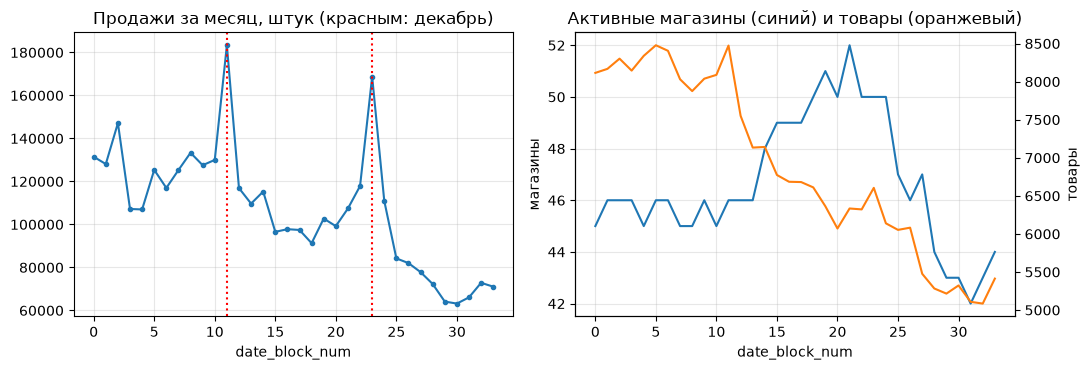

January totals (blocks 0, 12, 24): [131479, 116899, 110971]
December totals (blocks 11, 23): [183342, 168755]


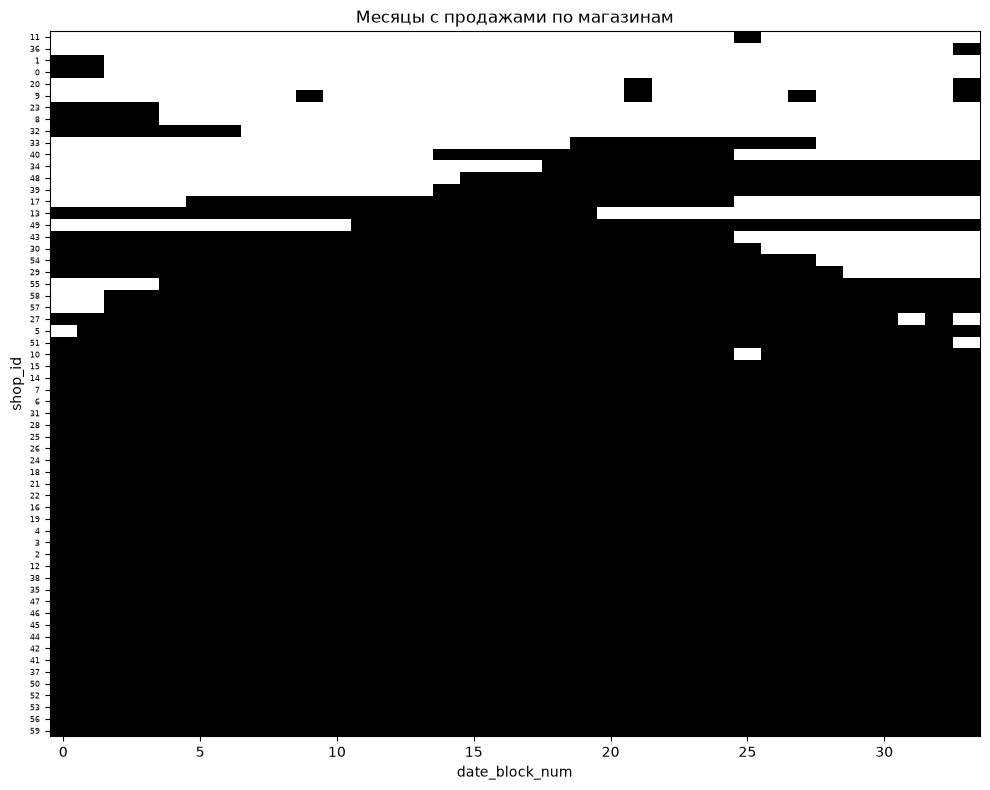

shops closed before month 33: 16 | active only in month 33: [36]


In [6]:
tot = sales.groupby("date_block_num").item_cnt_day.sum()
act = sales.groupby("date_block_num").agg(shops=("shop_id", "nunique"), items=("item_id", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tot.index, tot.values, marker="o", ms=3)
for m in (11, 23):
    ax[0].axvline(m, color="r", ls=":")
ax[0].set_title("Продажи за месяц, штук (красным: декабрь)"); ax[0].set_xlabel("date_block_num")
ax[1].plot(act.index, act["shops"])
ax[1].set_ylabel("магазины"); ax2 = ax[1].twinx(); ax2.plot(act.index, act["items"], color="C1")
ax2.set_ylabel("товары"); ax2.grid(False); ax[1].set_title("Активные магазины (синий) и товары (оранжевый)"); ax[1].set_xlabel("date_block_num")
save("time")
print("January totals (blocks 0, 12, 24):", tot[[0, 12, 24]].astype(int).tolist())
print("December totals (blocks 11, 23):", tot[[11, 23]].astype(int).tolist())

M = sales.groupby(["shop_id", "date_block_num"]).size().unstack(fill_value=0).reindex(columns=range(34), fill_value=0) > 0
M = M.loc[M.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(M.values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=6); ax.set_xlabel("date_block_num"); ax.set_ylabel("shop_id")
ax.set_title("Месяцы с продажами по магазинам"); ax.grid(False)
save("shop_activity")
print("shops closed before month 33:", int((~M[33]).sum()), "| active only in month 33:", M.index[(M.sum(axis=1) == 1) & M[33]].tolist())

## 6. Категории

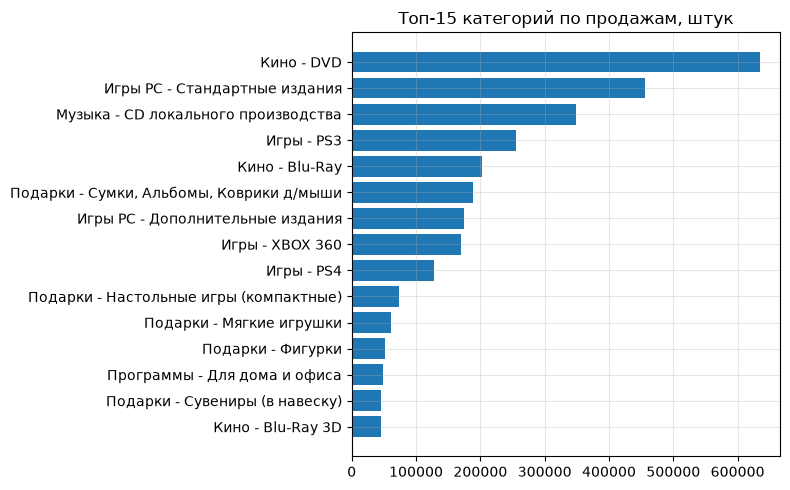

share of test rows with new item: 0.071
categories with new items: 39 of 62


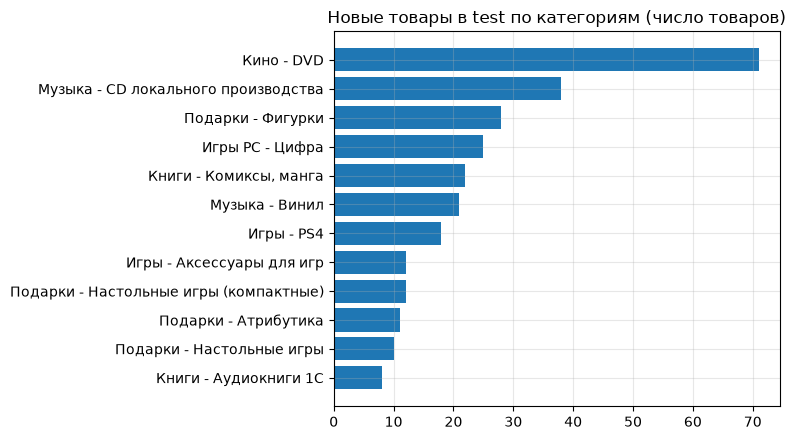

                  new_share   rows                                    name
item_category_id                                                          
40                    0.092  32340                              Кино - DVD
55                    0.057  28224     Музыка - CD локального производства
72                    0.146   8064                       Подарки - Фигурки
31                    0.090  11634                         Игры PC - Цифра
47                    0.148   6258                  Книги - Комиксы, манга
58                    0.094   9366                          Музыка - Винил
20                    0.131   5754                              Игры - PS4
25                    0.324   1554               Игры - Аксессуары для игр
65                    0.132   3822  Подарки - Настольные игры (компактные)
61                    0.073   6342                    Подарки - Атрибутика
64                    0.078   5376               Подарки - Настольные игры
45                    0.2

In [7]:
s = sales.merge(items[["item_id", "item_category_id"]], on="item_id")
top = s.groupby("item_category_id").item_cnt_day.sum().nlargest(15)
names = cats.set_index("item_category_id").item_category_name
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([names[i] for i in top.index][::-1], top.values[::-1]); ax.set_title("Топ-15 категорий по продажам, штук")
save("categories_top")

t = test.merge(items[["item_id", "item_category_id"]], on="item_id")
t["new"] = t.item_id.isin(new_items)
share = t.groupby("item_category_id").agg(new_share=("new", "mean"), rows=("new", "size"))
new_cnt = t[t.new].groupby("item_category_id").item_id.nunique().nlargest(12)
print("share of test rows with new item:", round(t.new.mean(), 3))
print("categories with new items:", t[t.new].item_category_id.nunique(), "of", t.item_category_id.nunique())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([names[i] for i in new_cnt.index][::-1], new_cnt.values[::-1]); ax.set_title("Новые товары в test по категориям (число товаров)")
save("categories_new")
print(share.loc[new_cnt.index].assign(name=[names[i] for i in new_cnt.index]).round(3).to_string())

## 7. Выводы

- Test это полное произведение 42 магазинов на 5100 товаров, поэтому валидацию нужно строить на такой же сетке (магазины и товары, активные в месяце), а не на парах из лога. На парах из лога среднее клипнутого таргета около 1.86, на сетке около 0.26.
- Около 86% строк сетки нулевые, а почти половина теста относится к срезам B и C, где продаж пары в прошлом нет. Метрику нужно считать отдельно по срезам A, B, C.
- Магазины 9 и 20 торговали в последнем месяце, но в тест не попали, поэтому их исключаем из обучающей сетки и из валидации.
- Дубли магазинов (0 и 57, 1 и 58, 10 и 11) объединяем по id, иначе история одного магазина разрывается.
- Выбросы (цена -1 и 307980, 2169 штук за день) убираем при загрузке. Возвраты оставляем: они входят в месячную сумму, а отрицательная сумма после клипа становится нулём.
- Таргет клипаем в [0, 20]. Строк выше 20 меньше процента, но именно они дают большие квадраты ошибок.
- Продажи падают год к году и есть сезонность с пиком в декабре, поэтому разбиение только по времени (валидация на последних месяцах), без перемешивания. Диагностический фолд на ноябре (месяц 22) отдельно проверяет сезон.